<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Minería de Datos · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Modelos lineales con TF-IDF</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Miguel A. Garcia, Nadia Ramos, Ángel J. Zamora</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

Este notebook compara baselines y modelos lineales (regresión logística, SVM lineal y Complement NB) sobre TF-IDF de palabras y caracteres, con validación cruzada agrupada por fuente. **Lee** `data/processed/corpus.parquet` (train + development preparados, con sus folds) y **no carga el test**. Escribe `resultados/cv_lineales.csv` (todas las combinaciones por fold), `resultados/seleccion_lineal.json` (configuración elegida) y figuras en `figuras/`.

## Contenido

    * [Sección 0: Configuración](#seccion-0)
* **[Metodología CRISP-DM: Modelado](#fase-modelado)**
    * [Sección 1: Datos y protocolo](#seccion-1)
    * [Sección 2: Baselines](#seccion-2)
    * [Sección 3: Representación y estructura](#seccion-3)
    * [Sección 4: El atajo del medio](#seccion-4)
    * [Sección 5: Búsqueda de hiperparámetros](#seccion-5)
    * [Sección 6: Selección χ² y bloque de estilo](#seccion-6)
    * [Sección 7: Diagnósticos](#seccion-7)
    * [Sección 8: Selección del modelo](#seccion-8)
    * [Sección 9: Comprobaciones solicitadas por el equipo](#seccion-9)
* **[Conclusiones](#conclusiones)**
    * [Sección 10: Resumen por sección](#seccion-10)
    * [Sección 11: Implicaciones para la evaluación](#seccion-11)
    * [Sección 12: Referencias](#seccion-12)

<a id="seccion-0"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 0: Configuración</span></div>

> **Qué se hace:** cargamos bibliotecas y fijamos las rejillas de búsqueda.
>
> **Qué se espera ver:** constantes justificadas antes de ver resultados.

### 0.1 Bibliotecas

In [1]:
# Manejo de datos
import json
import os
import time
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt

# Modelado
from joblib import Parallel, delayed
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.base import clone

# Funciones compartidas del proyecto
import utils_fakedes as uf
from utils_fakedes import guardar, guardar_csv

### 0.2 Constantes y rejillas

Las rejillas se fijan antes de ver resultados. Los valores de regularización crecen de forma aproximadamente geométrica (×3), porque el efecto de C y alpha es multiplicativo. En la etapa de representación cada modelo usa un valor central de su rejilla.

| Constante | Valores | Justificación |
|:--|:--|:--|
| `REJILLA['LR']` (C) | 0.3, 1, 3, 10, 30, 100 | Con TF-IDF normalizado L2, la regresión logística suele necesitar C ≥ 1 |
| `REJILLA['SVM']` (C) | 0.01, 0.03, 0.1, 0.3, 1, 3 | La SVM lineal satura antes; C > 3 casi no cambia la frontera |
| `REJILLA['CNB']` (alpha) | 0.01, 0.03, 0.1, 0.3, 1 | Suavizado de Laplace de débil a fuerte |
| `MIN_DF` | 1, 2, 5 | Desde todo el vocabulario hasta quitar términos de menos de 5 noticias |
| `MINUSCULAS` | True, False | El estilo (mayúsculas) puede ser señal; se prueba |
| `K_CHI2` | 1,000, 5,000, 20,000, todas | Reducción fuerte, media y leve frente a no reducir |

In [2]:
SEMILLA = uf.SEMILLA
COLORES_CLASE = uf.COLORES_CLASE
TINTA, TINTA_SUAVE = uf.TINTA, uf.TINTA_SUAVE
REJILLA = {'LR': [0.3, 1, 3, 10, 30, 100], 'SVM': [0.01, 0.03, 0.1, 0.3, 1, 3], 'CNB': [0.01, 0.03, 0.1, 0.3, 1]}
VALOR_CENTRAL = {'LR': 10, 'SVM': 0.3, 'CNB': 0.1}
MIN_DF, MINUSCULAS = [1, 2, 5], [True, False]
K_CHI2 = [1000, 5000, 20000, None]
COMPLEJIDAD_REP = {r: i for i, r in enumerate(uf.REPRESENTACIONES)}
COMPLEJIDAD_EST = {'solo titular': 0, 'solo texto': 1, 'concatenado': 2, 'bloques': 3}
uf.configurar_graficas()
pd.set_option('display.max_colwidth', 60)

### 0.3 Rutas

**Tabla 0.3.** Archivos que lee y escribe el notebook.

In [3]:
uf.crear_carpetas(uf.RUTA_RESULTADOS, uf.RUTA_FIGURAS)
pd.DataFrame({'archivo': ['data/processed/corpus.parquet', 'resultados/cv_lineales.csv', 'resultados/seleccion_lineal.json'],
              'uso': ['lectura: train + development preparados con folds', 'todas las combinaciones por fold', 'configuración elegida para evaluacion.ipynb']})

,archivo,uso
0,data/processed/corpus.parquet,lectura: train + development preparados con folds
1,resultados/cv_lineales.csv,todas las combinaciones por fold
2,resultados/seleccion_lineal.json,configuración elegida para evaluacion.ipynb


<a id="fase-modelado"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Modelado</span></div>

<a id="seccion-1"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 1: Datos y protocolo</span></div>

> **Qué se hace:** cargamos el corpus preparado y fijamos la regla de selección antes de entrenar.
>
> **Qué se espera ver:** 961 noticias en 5 folds agrupados por fuente, sin noticias del test.

#### Glosario de la sección
* **Validación cruzada agrupada:** cada fold valida con fuentes que el modelo no vio al entrenar.
* **Error estándar (SE):** sd de la métrica entre folds dividida entre √5; mide la incertidumbre de la media.
* **Regla de un error estándar:** entre las configuraciones cuya media está a menos de un SE de la mejor, se elige la más simple.

**Tabla 1.1.** Composición de los folds agrupados (leídos de disco; no se vuelven a partir).

In [4]:
corpus = pd.read_parquet(os.path.join(uf.RUTA_PROCESADOS, 'corpus.parquet'))
assert (corpus['particion'] != 'test').all()
corpus.groupby('fold_grupo').agg(noticias = ('id_unico', 'size'), pct_fake = ('y', lambda s: round(100 * s.mean(), 1)),
                                 fuentes = ('fuente', 'nunique'))

,noticias,pct_fake,fuentes
fold_grupo,,,
0,231,58.0,16
1,190,48.9,16
2,181,45.9,38
3,180,45.6,38
4,179,45.8,40


**Protocolo** (preparación de los datos, Sección 6): elegimos todo con validación cruzada de 5 folds agrupados por fuente (`fold_grupo`). En cada fold, vocabulario, IDF y selección χ² se ajustan solo con los 4 folds de entrenamiento. Luego se reentrena con todo `train` + `development` y se mide **una sola vez** en el test, en `evaluacion.ipynb`.

**Reglas fijadas antes de ver resultados:**

1. **Métrica de selección:** media de la F1 de *fake* en los 5 folds agrupados.
2. **Texto de entrada:** la versión sin nombres de medio (`*_sin_medio`). La versión con medio solo se mide como diagnóstico (Sección 4), porque las menciones de medios apuntan a "verdadera" en train y se debilitan en el test (análisis exploratorio, Sección 14).
3. **Desempate (regla de un error estándar):** entre las configuraciones cuya media queda a menos de un SE de la mejor, se elige la de menos atributos. Si siguen empatadas, se prefiere la regresión logística, porque da probabilidades para la API. *(Esta regla se revisó en la Sección 8.2, antes de tocar el test.)*
4. **Diferencias que cuentan:** una mejora menor que la sd entre folds no cuenta como mejora.

**Implementación:** para no repetir la vectorización (la parte lenta), cada fold se vectoriza una vez y sobre esa matriz se entrenan todos los clasificadores. Es equivalente a un `Pipeline` por fold; la Sección 8.3 lo verifica reconstruyendo el `Pipeline` del modelo elegido.

**Herramientas externas (Fase 9 del protocolo): No aplica.** No se usaron APIs de moderación ni modelos externos como atributos o como sistemas de referencia: la tarea es clasificar veracidad, no toxicidad (las categorías de una API de moderación, como *hate* o *violence*, no corresponden a *fake* / *true*), y las restricciones del proyecto excluyen APIs externas (análisis exploratorio, Sección 1.3). Un transformer en español (BETO) queda planeado como modelo propio en `notas/siguientes_pasos.md`.

In [5]:
def matrices_fold(df, k, columna_fold, **rep):
    '''
    Función que vectoriza un fold ajustando la representación solo con su parte de entrenamiento

    inputs:
    --------
        df (pandas.DataFrame): Corpus preparado
        k (int o str): Fold de validación
        columna_fold (str): Columna que define los folds
        rep (dict): Argumentos de uf.crear_representacion

    outputs:
    --------
        tuple: (k, X de entrenamiento, y de entrenamiento, X de validación, y de validación)
    '''
    entrenamiento, validacion = df[df[columna_fold] != k], df[df[columna_fold] == k]
    transformador = uf.crear_representacion(**rep)
    return (k, transformador.fit_transform(entrenamiento), entrenamiento['Category'].values,
            transformador.transform(validacion), validacion['Category'].values)

def evaluar_representacion(df, columna_fold, modelos, k_chi2 = (None,), **rep):
    '''
    Función que evalúa varios clasificadores sobre una misma representación en todos los folds

    inputs:
    --------
        df (pandas.DataFrame): Corpus preparado
        columna_fold (str): Columna que define los folds
        modelos (list): Pares (nombre del modelo, valor de regularización)
        k_chi2 (tuple): Números de atributos a conservar con χ² (None = todos)
        rep (dict): Argumentos de uf.crear_representacion

    outputs:
    --------
        pandas.DataFrame: Una fila por fold, k y modelo con la configuración, el número de atributos y las métricas
    '''
    folds = sorted(df[columna_fold].unique())
    matrices = Parallel(n_jobs = -1)(delayed(matrices_fold)(df, k, columna_fold, **rep) for k in folds)
    filas = []
    for k, X_ent, y_ent, X_val, y_val in matrices:
        for k_sel in k_chi2:
            if k_sel is not None and k_sel < X_ent.shape[1]:
                selector = SelectKBest(chi2, k = k_sel).fit(X_ent, y_ent)
                Xe, Xv = selector.transform(X_ent), selector.transform(X_val)
            else:
                Xe, Xv = X_ent, X_val
            for nombre, valor in modelos:
                pred = uf.crear_modelo(nombre, valor).fit(Xe, y_ent).predict(Xv)
                filas.append({**rep, 'k_chi2': k_sel, 'modelo': nombre, 'valor': valor, 'esquema': columna_fold, 'fold': k,
                              'n_atributos': Xe.shape[1], **uf.metricas(y_val, pred)})
    return pd.DataFrame(filas)

In [6]:
CLAVES = ['representacion', 'estructura', 'sin_medio', 'min_df', 'minusculas', 'estilo', 'k_chi2', 'modelo', 'valor']

def resumir(resultados):
    '''
    Función que resume los resultados por configuración (media, sd y SE entre folds)

    inputs:
    --------
        resultados (pandas.DataFrame): Salida de evaluar_representacion

    outputs:
    --------
        pandas.DataFrame: Una fila por configuración, ordenada de mayor a menor F1 de fake media
    '''
    r = resultados.copy()
    r['k_chi2'] = r['k_chi2'].fillna(0).astype(int)
    r = r.drop_duplicates(CLAVES + ['esquema', 'fold'])
    resumen = uf.resumir_cv(r, por = CLAVES)
    resumen['n_atributos'] = r.groupby(CLAVES)['n_atributos'].mean().round(0)
    return resumen.reset_index()

<a id="seccion-2"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 2: Baselines</span></div>

> **Qué se hace:** medimos la clase mayoritaria, una predicción aleatoria estratificada y réplicas de los dos baselines clásicos oficiales.
>
> **Qué se espera ver:** F1 de fake cercana a 0 para la mayoritaria, cercana a 0.5 para la aleatoria, y valores intermedios para las réplicas.

⚠️ Las réplicas son aproximadas: el overview describe lematización, eliminación de puntuación y números y minúsculas, sin dar el código. Usamos `CountVectorizer` (minúsculas, sin lematizar) con SVM lineal sobre titular + texto con los nombres de medio. Sus números oficiales en test (.7217 y .7063) no se comparan con los de CV.

**Tabla 2.1.** Baselines en CV agrupada (media ± sd de 5 folds).

In [7]:
def baselines(entrenamiento, validacion):
    '''
    Función que entrena los baselines en un fold y predice su validación

    inputs:
    --------
        entrenamiento (pandas.DataFrame): Folds de entrenamiento
        validacion (pandas.DataFrame): Fold de validación

    outputs:
    --------
        dict: Predicciones de cada baseline
    '''
    X0_ent, X0_val = np.zeros((len(entrenamiento), 1)), np.zeros((len(validacion), 1))
    salida = {'Clase mayoritaria': DummyClassifier(strategy = 'most_frequent').fit(X0_ent, entrenamiento['Category']).predict(X0_val),
              'Aleatoria estratificada': DummyClassifier(strategy = 'stratified', random_state = SEMILLA).fit(X0_ent, entrenamiento['Category']).predict(X0_val)}
    for nombre in ['BoW + SVM', '3-gramas de caracteres + SVM']:
        salida[f'Réplica {nombre}'] = uf.construir_replica(nombre).fit(entrenamiento, entrenamiento['Category']).predict(validacion)
    return salida

cv_baselines = uf.evaluar_por_folds(corpus, 'fold_grupo', baselines)
resumen_baselines = uf.resumir_cv(cv_baselines)
resumen_baselines.round(3)

,F1_fake_mean,F1_fake_std,F1_macro_mean,F1_macro_std,accuracy_mean,accuracy_std,F1_fake_se
config,,,,,,,
Réplica BoW + SVM,0.707,0.051,0.721,0.043,0.722,0.043,0.023
Réplica 3-gramas de caracteres + SVM,0.679,0.070,0.695,0.063,0.696,0.063,0.031
Aleatoria estratificada,0.495,0.019,0.499,0.021,0.500,0.021,0.008
Clase mayoritaria,0.377,0.344,0.315,0.015,0.461,0.032,0.154


**Qué se observa.** La réplica BoW + SVM obtiene una F1 de fake de 0.707 ± 0.051 y la de 3-gramas de caracteres, 0.679 ± 0.070. El orden coincide con el oficial en test (.7217 y .7063). La aleatoria estratificada queda en 0.495 ± 0.019. La clase mayoritaria da 0.377 ± 0.344: en los folds 0 y 1 la clase mayoritaria del entrenamiento es *True* (F1 = 0) y en los folds 2 a 4 es *Fake* (F1 ≈ 0.63), por el desbalance del fold 0. **La réplica BoW + SVM es la referencia que un modelo debe superar en CV; un modelo por debajo de 0.707 no aporta.**

<a id="seccion-3"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 3: Representación y estructura</span></div>

> **Qué se hace:** comparamos 4 representaciones TF-IDF × 4 estructuras (solo titular, solo texto, concatenado, bloques) × 3 modelos, con la regularización central y el texto sin medio.
>
> **Qué se espera ver:** que el texto aporte más que el titular y que los caracteres ayuden frente al vocabulario nuevo del test.

#### Glosario de la sección
* **TF-IDF:** peso de un término: frecuencia en la noticia (en escala logarítmica) por la rareza en el corpus.
* **char_wb (2,5):** n-gramas de 2 a 5 caracteres dentro de cada palabra; robustos a variantes y palabras nuevas.
* **Bloques:** titular y texto con vectorizadores separados cuyas matrices se pegan (`hstack`): "vacuna" en el titular y en el texto son columnas distintas.
* **Complement NB:** Naive Bayes que estima cada clase con los documentos de la otra; más estable con clases o longitudes desiguales.

Son 16 representaciones × 5 folds = 80 vectorizaciones; los 3 modelos comparten cada una. Ajustes fijos: `min_df = 2`, minúsculas y `sublinear_tf`.

In [8]:
inicio = time.time()
modelos_centrales = [(m, VALOR_CENTRAL[m]) for m in REJILLA]
etapa1 = pd.concat([evaluar_representacion(corpus, 'fold_grupo', modelos_centrales, representacion = r, estructura = e,
                                           sin_medio = True, min_df = 2, minusculas = True, estilo = False)
                    for r in uf.REPRESENTACIONES for e in uf.ESTRUCTURAS], ignore_index = True)
resumen1 = resumir(etapa1)
f'{len(etapa1)} filas (configuración × fold) en {time.time() - inicio:.0f} s'

'240 filas (configuración × fold) en 225 s'

**Tabla 3.1.** Las 10 mejores combinaciones de la etapa 1 (todas se guardan en `cv_lineales.csv`).

In [9]:
columnas_tabla = ['representacion', 'estructura', 'modelo', 'valor', 'F1_fake_mean', 'F1_fake_std', 'F1_fake_se', 'F1_macro_mean', 'n_atributos']
resumen1[columnas_tabla].head(10).round(3)

,representacion,estructura,modelo,valor,F1_fake_mean,F1_fake_std,F1_fake_se,F1_macro_mean,n_atributos
0,"palabras (1,2) + caracteres (2,5)",solo texto,LR,10.0,0.713,0.072,0.032,0.742,102384.0
1,"palabras (1,2) + caracteres (2,5)",solo texto,SVM,0.3,0.711,0.071,0.032,0.740,102384.0
2,"caracteres (2,5)",solo texto,LR,10.0,0.710,0.060,0.027,0.738,65485.0
3,"palabras (1,2) + caracteres (2,5)",concatenado,SVM,0.3,0.702,0.082,0.037,0.733,103655.0
4,"caracteres (2,5)",solo texto,SVM,0.3,0.702,0.055,0.024,0.730,65485.0
5,"palabras (1,2)",solo texto,LR,10.0,0.702,0.100,0.045,0.734,36899.0
6,"palabras (1,1)",solo texto,LR,10.0,0.701,0.093,0.042,0.733,11897.0
7,"palabras (1,2) + caracteres (2,5)",concatenado,LR,10.0,0.701,0.078,0.035,0.731,103655.0
8,"caracteres (2,5)",concatenado,SVM,0.3,0.700,0.066,0.030,0.730,66051.0
9,"palabras (1,2)",solo texto,SVM,0.3,0.698,0.113,0.051,0.730,36899.0


Una figura por modelo con barras agrupadas: representación en el eje x y estructura como color; la línea vertical es la sd entre folds.

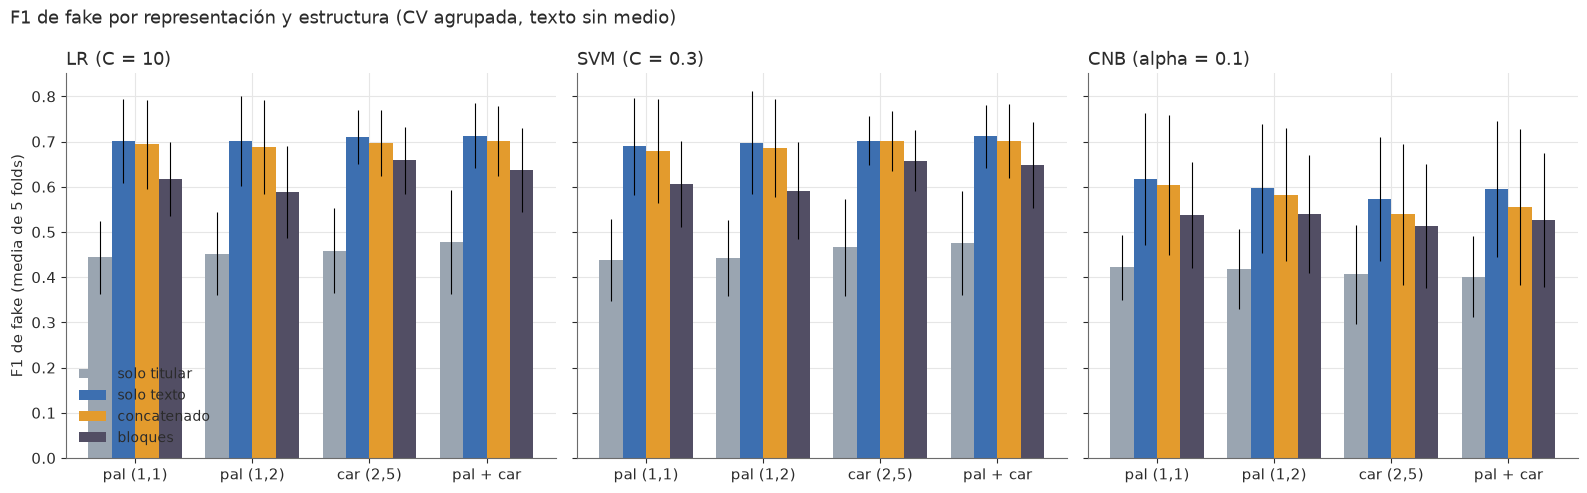

In [10]:
colores_est = dict(zip(uf.ESTRUCTURAS, ['#9aa5b1', '#3D6FB0', '#e39b2d', '#524e64']))
fig, ejes = plt.subplots(1, 3, figsize = (16, 5), sharey = True)
for ax, modelo in zip(ejes, REJILLA):
    sub = resumen1[resumen1['modelo'] == modelo]
    for j, est in enumerate(uf.ESTRUCTURAS):
        fila = sub[sub['estructura'] == est].set_index('representacion').loc[uf.REPRESENTACIONES]
        x = np.arange(len(uf.REPRESENTACIONES)) + (j - 1.5) * 0.2
        ax.bar(x, fila['F1_fake_mean'], width = 0.2, yerr = fila['F1_fake_std'], color = colores_est[est], label = est, error_kw = {'lw': 0.8})
    ax.set_xticks(np.arange(len(uf.REPRESENTACIONES)), ['pal (1,1)', 'pal (1,2)', 'car (2,5)', 'pal + car'])
    ax.set_title(f'{modelo} ({"alpha" if modelo == "CNB" else "C"} = {VALOR_CENTRAL[modelo]})')
ejes[0].set_ylabel('F1 de fake (media de 5 folds)')
ejes[0].legend(loc = 'lower left', fontsize = 10)
fig.suptitle('F1 de fake por representación y estructura (CV agrupada, texto sin medio)', x = 0.01, ha = 'left', fontsize = 13)
fig.tight_layout()
guardar(fig, '3_1_representacion_estructura')
plt.show()

**Qué se observa.**

* **Texto frente a titular.** El texto solo es la mejor estructura para los 3 modelos (media de las 4 representaciones: LR 0.707, SVM 0.700, CNB 0.595). El titular solo queda en 0.458, 0.456 y 0.412.
* **Bloques frente a concatenado.** Concatenar (LR 0.695) es mejor que bloques separados (LR 0.626). Una explicación probable: en bloques, el titular recibe una matriz normalizada del mismo peso que el texto, y es la parte más débil.
* **Representaciones.** Las diferencias entre representaciones son pequeñas comparadas con la sd entre folds (0.06 a 0.11). La mejor combinación es palabras (1,2) + caracteres (2,5) sobre el texto solo, con LR (0.713 ± 0.072) y SVM (0.711 ± 0.071); caracteres solos con LR dan 0.710 ± 0.060.
* **Complement NB** queda siempre por debajo (máximo 0.617).

**Seguimos con el texto solo y la representación combinada para LR y SVM. Agregar el titular no ayuda en CV; GDUFS_DM lo concatenaba, pero su modelo era un transformer.**

<a id="seccion-4"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 4: El atajo del medio</span></div>

> **Qué se hace:** comparamos, para la mejor representación de cada modelo, el texto con los nombres de medio contra el texto sin ellos, fold por fold.
>
> **Qué se espera ver:** que el texto con medio puntúe igual o más alto en CV; si es así, el modelo usa las menciones del medio.

⚠️ Este resultado no cambia la regla 2: se sigue eligiendo con el texto sin medio.

**Tabla 4.1.** F1 de fake con y sin nombres de medio y diferencia pareada por fold (con − sin).

In [11]:
mejores1 = resumen1.groupby('modelo').head(1).set_index('modelo')
filas_medio = []
for modelo, fila in mejores1.iterrows():
    for sin_medio in [True, False]:
        filas_medio.append(evaluar_representacion(corpus, 'fold_grupo', [(modelo, fila['valor'])], representacion = fila['representacion'],
                                                  estructura = fila['estructura'], sin_medio = sin_medio, min_df = 2, minusculas = True, estilo = False))
etapa_medio = pd.concat(filas_medio, ignore_index = True)
pareado = etapa_medio.pivot_table(index = ['modelo', 'fold'], columns = 'sin_medio', values = 'F1_fake')
pareado['diferencia'] = pareado[False] - pareado[True]
tabla_medio = pareado.groupby('modelo').agg(sin_medio = (True, 'mean'), con_medio = (False, 'mean'),
                                            diferencia_media = ('diferencia', 'mean'), diferencia_sd = ('diferencia', 'std'),
                                            folds_con_mejora = ('diferencia', lambda d: int((d > 0).sum())))
tabla_medio.round(3)

,sin_medio,con_medio,diferencia_media,diferencia_sd,folds_con_mejora
modelo,,,,,
CNB,0.617,0.618,0.001,0.002,1
LR,0.713,0.717,0.003,0.005,2
SVM,0.711,0.713,0.001,0.003,1


**Qué se observa.** Usar el texto con los nombres de medio cambia la F1 de fake en +0.001 (CNB), +0.003 (LR) y +0.001 (SVM). Las sd de la diferencia van de 0.002 a 0.005, y solo 1 o 2 de los 5 folds mejoran. **Borrar los nombres de medio no cuesta desempeño en CV: en esta representación el atajo no está en los nombres sino en el estilo de cada medio, que el diagnóstico de la Sección 7.1 sí capta.**

<a id="seccion-5"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 5: Búsqueda de hiperparámetros</span></div>

> **Qué se hace:** para la mejor representación y estructura de cada modelo, recorremos regularización × `min_df` × minúsculas y registramos todas las combinaciones.
>
> **Qué se espera ver:** una mejora pequeña sobre la etapa 1 y, quizá, algún ganador en la orilla de la rejilla.

Las combinaciones que comparten representación reutilizan la vectorización. **Tabla 5.1.** Número de combinaciones por modelo.

In [12]:
inicio = time.time()
filas2 = []
for (rep, est), grupo in mejores1.reset_index().groupby(['representacion', 'estructura']):
    modelos = [(m, v) for m in grupo['modelo'] for v in REJILLA[m]]
    for min_df in MIN_DF:
        for minusculas in MINUSCULAS:
            filas2.append(evaluar_representacion(corpus, 'fold_grupo', modelos, representacion = rep, estructura = est,
                                                 sin_medio = True, min_df = min_df, minusculas = minusculas, estilo = False))
etapa2 = pd.concat(filas2, ignore_index = True)
resumen2 = resumir(etapa2)
resumen2.groupby('modelo').size().rename('combinaciones').to_frame().assign(segundos = round(time.time() - inicio))

,combinaciones,segundos
modelo,,
CNB,30,293
LR,36,293
SVM,36,293


**Tabla 5.2.** Mejor combinación de cada modelo y si cae en la orilla de su rejilla.

In [13]:
def en_orilla(fila):
    '''
    Función que indica qué hiperparámetros del ganador están en el extremo de su rejilla

    inputs:
    --------
        fila (pandas.Series): Configuración con 'modelo', 'valor' y 'min_df'

    outputs:
    --------
        str: Hiperparámetros en la orilla, o '✅ ninguno'
    '''
    orillas = []
    if fila['valor'] in (min(REJILLA[fila['modelo']]), max(REJILLA[fila['modelo']])):
        orillas.append('regularización')
    if fila['min_df'] in (min(MIN_DF), max(MIN_DF)):
        orillas.append('min_df')
    return '⚠️ ' + ', '.join(orillas) if orillas else '✅ ninguno'

mejores2 = resumen2.groupby('modelo').head(1).copy()
mejores2['orilla'] = mejores2.apply(en_orilla, axis = 1)
mejores2[['modelo', 'representacion', 'estructura', 'valor', 'min_df', 'minusculas', 'F1_fake_mean', 'F1_fake_std', 'F1_fake_se', 'orilla']].round(3)

,modelo,representacion,estructura,valor,min_df,minusculas,F1_fake_mean,F1_fake_std,F1_fake_se,orilla
0,LR,"palabras (1,2) + caracteres (2,5)",solo texto,10.0,5,True,0.731,0.071,0.032,⚠️ min_df
2,SVM,"palabras (1,2) + caracteres (2,5)",solo texto,0.3,5,True,0.727,0.076,0.034,⚠️ min_df
67,CNB,"palabras (1,1)",solo texto,1.0,5,False,0.676,0.141,0.063,"⚠️ regularización, min_df"


Si un hiperparámetro ganador está en la orilla, ampliamos la rejilla en esa dirección con los demás ajustes del ganador: la regularización dos pasos (×3) y `min_df` a 10 y 20 (con toda la rejilla de regularización del modelo). **Tabla 5.3.** Combinaciones de la ampliación.

In [14]:
MIN_DF_EXTRA = [10, 20]
ampliaciones = []
for _, f in mejores2.iterrows():
    rejilla = REJILLA[f['modelo']]
    rep_f = dict(representacion = f['representacion'], estructura = f['estructura'], sin_medio = True,
                 minusculas = bool(f['minusculas']), estilo = False)
    extra = [rejilla[-1] * 3, rejilla[-1] * 9] if f['valor'] == max(rejilla) else [rejilla[0] / 3, rejilla[0] / 9] if f['valor'] == min(rejilla) else []
    if extra:
        ampliaciones.append(evaluar_representacion(corpus, 'fold_grupo', [(f['modelo'], v) for v in extra], min_df = int(f['min_df']), **rep_f))
    if f['min_df'] == max(MIN_DF):
        for min_df in MIN_DF_EXTRA:
            ampliaciones.append(evaluar_representacion(corpus, 'fold_grupo', [(f['modelo'], v) for v in rejilla + extra], min_df = min_df, **rep_f))
etapa2b = pd.concat(ampliaciones, ignore_index = True) if ampliaciones else etapa2.iloc[:0]
resumen2b = resumir(etapa2b)
resumen2b.groupby(['modelo', 'min_df']).agg(combinaciones = ('valor', 'size'), mejor_F1 = ('F1_fake_mean', 'max')).round(3)

combinaciones  mejor_F1
modelo min_df                         
CNB    5                   2     0.638
       10                  7     0.681
       20                  7     0.690
LR     10                  6     0.725
       20                  6     0.730
SVM    10                  6     0.729
       20                  6     0.733

**Tabla 5.4.** Ganador de cada modelo después de la ampliación y orilla respecto a la rejilla ampliada.

In [15]:
resumen2_todo = resumir(pd.concat([etapa2, etapa2b], ignore_index = True))
def en_orilla_ampliada(fila):
    '''
    Función que revisa si el ganador sigue en la orilla de la rejilla ya ampliada

    inputs:
    --------
        fila (pandas.Series): Configuración con 'modelo', 'valor' y 'min_df'

    outputs:
    --------
        str: Hiperparámetros en la orilla ampliada, o '✅ ninguno'
    '''
    sub = resumen2_todo[resumen2_todo['modelo'] == fila['modelo']]
    orillas = [n for n, c in [('regularización', 'valor'), ('min_df', 'min_df')] if fila[c] in (sub[c].min(), sub[c].max())]
    return '⚠️ ' + ', '.join(orillas) if orillas else '✅ ninguno'
mejores_final = resumen2_todo.groupby('modelo').head(1).copy()
mejores_final['orilla'] = mejores_final.apply(en_orilla_ampliada, axis = 1)
mejores_final[['modelo', 'representacion', 'estructura', 'valor', 'min_df', 'minusculas', 'F1_fake_mean', 'F1_fake_std', 'F1_fake_se', 'orilla']].round(3)

,modelo,representacion,estructura,valor,min_df,minusculas,F1_fake_mean,F1_fake_std,F1_fake_se,orilla
0,SVM,"palabras (1,2) + caracteres (2,5)",solo texto,0.1,20,True,0.733,0.093,0.041,⚠️ min_df
1,LR,"palabras (1,2) + caracteres (2,5)",solo texto,10.0,5,True,0.731,0.071,0.032,✅ ninguno
78,CNB,"palabras (1,1)",solo texto,1.0,20,False,0.690,0.145,0.065,⚠️ min_df


La curva de validación muestra la F1 media según la regularización, con los demás ajustes del ganador final de cada modelo.

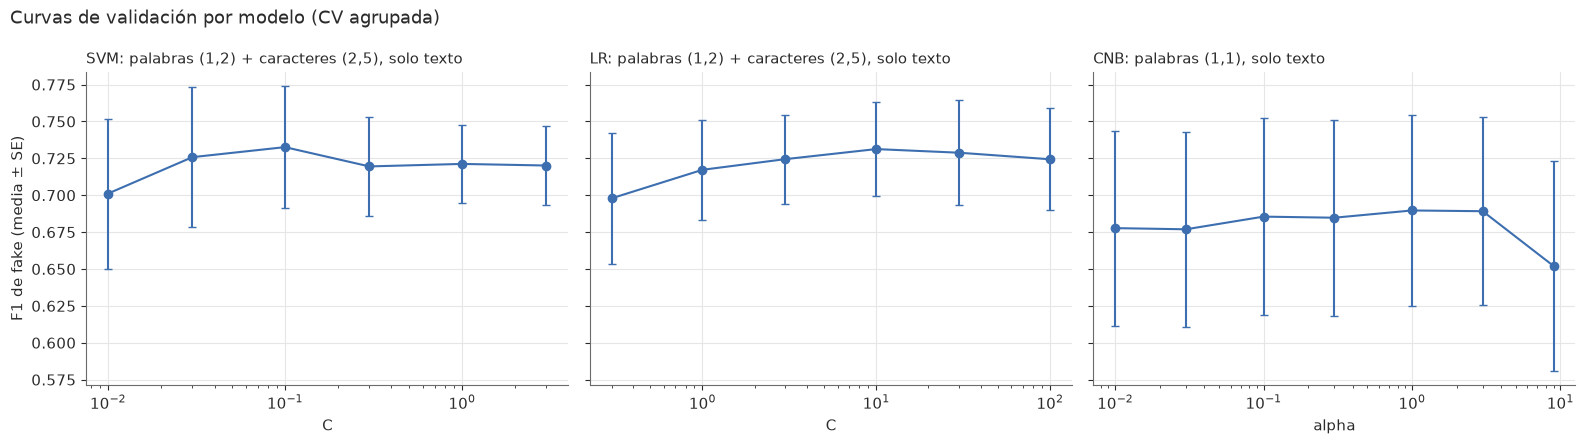

In [16]:
fig, ejes = plt.subplots(1, 3, figsize = (16, 4.5), sharey = True)
for ax, (_, g) in zip(ejes, mejores_final.iterrows()):
    curva = resumen2_todo[(resumen2_todo['modelo'] == g['modelo']) & (resumen2_todo['min_df'] == g['min_df']) &
                          (resumen2_todo['minusculas'] == g['minusculas'])].sort_values('valor')
    ax.errorbar(curva['valor'], curva['F1_fake_mean'], yerr = curva['F1_fake_se'], marker = 'o', color = '#3D6FB0', capsize = 3)
    ax.set_xscale('log')
    ax.set_xlabel('alpha' if g['modelo'] == 'CNB' else 'C')
    ax.set_title(f"{g['modelo']}: {g['representacion']}, {g['estructura']}", fontsize = 11)
ejes[0].set_ylabel('F1 de fake (media ± SE)')
fig.suptitle('Curvas de validación por modelo (CV agrupada)', x = 0.01, ha = 'left', fontsize = 13)
fig.tight_layout()
guardar(fig, '5_1_curvas_validacion')
plt.show()

**Qué se observa.**

* **En la rejilla original** (Tabla 5.2), los ganadores de LR (C = 10) y SVM (C = 0.3) quedaron en `min_df = 5`, la orilla. CNB quedó además en la orilla de alpha (1); al ampliarla a 3 y 9 empeora (0.638 y 0.601).
* **Al ampliar `min_df` a 10 y 20** (Tabla 5.3), la F1 casi no cambia: LR 0.731 → 0.725 → 0.730 y SVM 0.727 → 0.729 → 0.733. El ganador final de SVM (`min_df = 20`, C = 0.1; 0.733 ± 0.093) sigue en la orilla, pero la curva es plana: las diferencias son menores que 0.01 y el SE es 0.04, así que no seguimos ampliando. El de LR (C = 10, `min_df = 5`; 0.731 ± 0.071) ya no está en la orilla.
* **Minúsculas.** Las tres mejores de LR y SVM usan minúsculas. CNB prefiere conservar mayúsculas, pero queda en 0.690 ± 0.145.

**LR y SVM empatan dentro de un SE (0.731 contra 0.733); la búsqueda de hiperparámetros mejora la etapa 1 en apenas 0.02, menos que la sd entre folds.**

<a id="seccion-6"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 6: Selección χ² y bloque de estilo</span></div>

> **Qué se hace:** sobre la mejor configuración global de la Sección 5 probamos reducir atributos con χ² y agregar los 10 rasgos de estilo escalados como bloque aparte.
>
> **Qué se espera ver:** que χ² reduzca atributos sin perder F1 y que el estilo aporte poco (análisis exploratorio, Sección 10).

#### Glosario de la sección
* **Selección χ²:** conserva los k términos con mayor estadístico χ² de dependencia con la clase, calculado solo con el train del fold.

**Tabla 6.1.** F1 de fake según k (χ²) y con el bloque de estilo.

In [17]:
mejor2 = resumen2_todo.iloc[0]
rep_mejor = dict(representacion = mejor2['representacion'], estructura = mejor2['estructura'], sin_medio = True,
                 min_df = int(mejor2['min_df']), minusculas = bool(mejor2['minusculas']))
modelo_mejor = [(mejor2['modelo'], mejor2['valor'])]
etapa_chi2 = evaluar_representacion(corpus, 'fold_grupo', modelo_mejor, k_chi2 = tuple(K_CHI2), estilo = False, **rep_mejor)
etapa_estilo = evaluar_representacion(corpus, 'fold_grupo', modelo_mejor, estilo = True, **rep_mejor)
resumen6 = resumir(pd.concat([etapa_chi2, etapa_estilo], ignore_index = True))
resumen6[['k_chi2', 'estilo', 'F1_fake_mean', 'F1_fake_std', 'F1_fake_se', 'F1_macro_mean', 'n_atributos']].round(3)

,k_chi2,estilo,F1_fake_mean,F1_fake_std,F1_fake_se,F1_macro_mean,n_atributos
0,0,False,0.733,0.093,0.041,0.754,18252.0
1,20000,False,0.733,0.093,0.041,0.754,18252.0
2,5000,False,0.714,0.114,0.051,0.738,5000.0
3,0,True,0.710,0.049,0.022,0.733,18262.0
4,1000,False,0.702,0.120,0.054,0.724,1000.0


**Qué se observa.** Sobre la mejor configuración (SVM, 18,252 atributos, 0.733 ± 0.093), la selección χ² empeora al reducir: 0.714 con k = 5,000 y 0.702 con k = 1,000 (k = 20,000 no cambia nada porque supera el número de atributos). El bloque de estilo baja la media a 0.710 pero también la sd, de 0.093 a 0.049: hace al modelo más estable entre folds sin mejorar el promedio. **Ninguna extensión mejora la media; el estilo podría valer la pena si la estabilidad importa, y se revisa en `modelo_arboles.ipynb`.**

<a id="seccion-7"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 7: Diagnósticos</span></div>

> **Qué se hace:** medimos cuánto cambia el puntaje con folds aleatorios y cuánto cae al validar con un tema que no se vio al entrenar.
>
> **Qué se espera ver:** puntajes más altos con folds aleatorios (el modelo reconoce medios) y caídas en temas nuevos.

⚠️ Los diagnósticos no se usan para elegir.

### 7.1 Folds agrupados frente a aleatorios (Tabla 7.1)

**Tabla 7.1.** Mejor configuración de cada modelo con ambos esquemas, y con el texto con medio en folds aleatorios.

In [18]:
filas7 = []
for _, g in mejores_final.iterrows():
    for esquema in ['fold_grupo', 'fold_aleatorio']:
        for sin_medio in [True, False]:
            filas7.append(evaluar_representacion(corpus, esquema, [(g['modelo'], g['valor'])], representacion = g['representacion'],
                                                 estructura = g['estructura'], sin_medio = sin_medio, min_df = int(g['min_df']),
                                                 minusculas = bool(g['minusculas']), estilo = False))
etapa7 = pd.concat(filas7, ignore_index = True)
tabla7 = etapa7.groupby(['modelo', 'sin_medio', 'esquema'])['F1_fake'].agg(['mean', 'std']).unstack('esquema')
tabla7.columns = [f'{e}_{m}' for m, e in tabla7.columns]
tabla7['aleatorio − agrupado'] = tabla7['fold_aleatorio_mean'] - tabla7['fold_grupo_mean']
tabla7.round(3)

fold_aleatorio_mean  fold_grupo_mean  fold_aleatorio_std  \
modelo sin_medio                                                             
CNB    False                    0.789            0.691               0.025   
       True                     0.790            0.690               0.023   
LR     False                    0.842            0.730               0.035   
       True                     0.838            0.731               0.034   
SVM    False                    0.829            0.736               0.028   
       True                     0.828            0.733               0.029   

                  fold_grupo_std  aleatorio − agrupado  
modelo sin_medio                                        
CNB    False               0.144                 0.098  
       True                0.145                 0.101  
LR     False               0.071                 0.112  
       True                0.071                 0.107  
SVM    False               0.088                 0.092  
       True                0.093                 0.095

**Qué se observa.** Con folds aleatorios la F1 de fake sube entre 0.092 y 0.112 (LR: 0.838 contra 0.731; SVM: 0.828 contra 0.733; CNB: 0.790 contra 0.690), y la sd baja a la mitad. El texto con medio en folds aleatorios apenas cambia (≤ 0.004). **Hallazgo: un 0.1 de F1 viene de reconocer medios ya vistos, por su estilo y no por su nombre. Una validación sin agrupar (como validar con `development`) habría reportado cerca de 0.84; esperamos que el test, con 66 % de fuentes nuevas, quede más cerca del 0.73 agrupado o por debajo.**

### 7.2 Validación con un tema nuevo (Tabla 7.2)

Con la mejor configuración global, cada tema de la versión 1.0 se valida una vez con un modelo entrenado en los otros 8 (*leave-one-topic-out*). **Tabla 7.2.** F1 de fake por tema no visto.

In [19]:
loto = evaluar_representacion(corpus, 'Topic', modelo_mejor, estilo = False, **rep_mejor)
tabla_loto = loto[['fold', 'F1_fake', 'F1_macro', 'accuracy']].rename(columns = {'fold': 'tema validado'})
tabla_loto['noticias'] = tabla_loto['tema validado'].map(corpus['Topic'].value_counts())
tabla_loto.sort_values('F1_fake').round(3)

,tema validado,F1_fake,F1_macro,accuracy,noticias
6,Security,0.714,0.714,0.714,42
3,Health,0.744,0.760,0.761,46
0,Economy,0.750,0.801,0.814,43
8,Sport,0.788,0.761,0.764,123
4,Politics,0.807,0.824,0.826,321
2,Entertainment,0.815,0.750,0.767,146
5,Science,0.825,0.840,0.841,88
7,Society,0.859,0.846,0.847,131
1,Education,0.909,0.905,0.905,21


**Qué se observa.** Validando con un tema no visto, la F1 de fake va de 0.714 (Security, 42 noticias) a 0.909 (Education, 21). Todos los temas superan el 0.733 agrupado por fuente menos Security. ⚠️ Este diagnóstico no agrupa por fuente: los medios de cada tema aparecen en los demás, así que el tema nuevo pesa menos que el medio nuevo. **El cambio de tema por sí solo no derrumba el modelo, en línea con el overview (COVID-19 no fue más difícil); el riesgo principal sigue siendo el medio.**

<a id="seccion-8"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 8: Selección del modelo</span></div>

> **Qué se hace:** aplicamos la regla de selección sobre todas las configuraciones con texto sin medio, la revisamos y guardamos la elegida.
>
> **Qué se espera ver:** una configuración más simple que la de mayor media si la diferencia es menor que un SE.

### 8.1 Regla original (Tabla 8.1)

**Tabla 8.1.** Configuraciones dentro de un SE de la mejor, ordenadas por número de atributos (regla fijada en la Sección 1).

In [20]:
todas = resumir(pd.concat([etapa1, etapa2, etapa2b, etapa_chi2, etapa_estilo], ignore_index = True))
todas = todas[todas['sin_medio']].drop_duplicates(CLAVES).sort_values('F1_fake_mean', ascending = False).reset_index(drop = True)
umbral = todas.loc[0, 'F1_fake_mean'] - todas.loc[0, 'F1_fake_se']
candidatas = todas[todas['F1_fake_mean'] >= umbral].assign(no_lr = lambda d: d['modelo'] != 'LR').sort_values(['n_atributos', 'no_lr'])
elegida_original = candidatas.iloc[0]
print(f'{len(candidatas)} configuraciones dentro de un SE (umbral = {umbral:.3f}); se muestran las 10 con menos atributos')
candidatas[columnas_tabla + ['min_df', 'minusculas', 'k_chi2', 'estilo']].head(10).round(3)

91 configuraciones dentro de un SE (umbral = 0.691); se muestran las 10 con menos atributos


,representacion,estructura,modelo,valor,F1_fake_mean,F1_fake_std,F1_fake_se,F1_macro_mean,n_atributos,min_df,minusculas,k_chi2,estilo
65,"palabras (1,2) + caracteres (2,5)",solo texto,SVM,0.1,0.702,0.120,0.054,0.724,1000.0,20,True,1000,False
39,"palabras (1,2) + caracteres (2,5)",solo texto,SVM,0.1,0.714,0.114,0.051,0.738,5000.0,20,True,5000,False
70,"palabras (1,1)",solo texto,LR,10.0,0.701,0.093,0.042,0.733,11897.0,2,True,0,False
84,"palabras (1,1)",concatenado,LR,10.0,0.694,0.098,0.044,0.726,12032.0,2,True,0,False
3,"palabras (1,2) + caracteres (2,5)",solo texto,LR,1.0,0.730,0.095,0.043,0.752,18252.0,20,True,0,False
7,"palabras (1,2) + caracteres (2,5)",solo texto,LR,100.0,0.726,0.064,0.029,0.750,18252.0,20,True,0,False
10,"palabras (1,2) + caracteres (2,5)",solo texto,LR,0.3,0.725,0.102,0.046,0.745,18252.0,20,True,0,False
13,"palabras (1,2) + caracteres (2,5)",solo texto,LR,3.0,0.725,0.077,0.034,0.747,18252.0,20,True,0,False
20,"palabras (1,2) + caracteres (2,5)",solo texto,LR,30.0,0.722,0.064,0.029,0.745,18252.0,20,True,0,False
21,"palabras (1,2) + caracteres (2,5)",solo texto,LR,10.0,0.721,0.077,0.034,0.746,18252.0,20,True,0,False


**Qué se observa.** La regla original admite 91 configuraciones dentro de un SE (umbral 0.691) y elige la de menos atributos: SVM con χ² (k = 1,000), con F1 de 0.702 ± 0.120. Es menor que la réplica BoW + SVM (0.707) y tiene la sd más alta del grupo. **La regla original falla en este caso; la revisamos en 8.2.**

### 8.2 Revisión de la regla (Tabla 8.2)

⚠️ **Cambio posterior a ver los resultados de CV y antes de tocar el test. La regla revisada fue validada por el equipo el 22 de noviembre de 2026.** La regla original elige una configuración con F1 media menor que la réplica del baseline BoW + SVM (Tabla 2.1), lo que contradice el propósito de la selección. Dos fallas: (1) con SE ≈ 0.04, un error estándar admite casi cualquier configuración razonable; (2) "menos atributos" premia la selección χ², que en realidad agrega un paso supervisado al proceso. La regla revisada:

1. Candidatas: dentro de un SE de la mejor **y** con F1 media mayor que la réplica BoW + SVM en CV.
2. Entre ellas, se prefieren los procesos sin χ² ni bloque de estilo, luego la regresión logística (da probabilidades) y luego menos atributos.

La configuración de la regla original se conserva en `seleccion_lineal.json` y se reportará en el test como sistema secundario, no para elegir.

**Tabla 8.2.** Candidatas de la regla revisada, en el orden de preferencia.

In [21]:
f1_bow = resumen_baselines.loc['Réplica BoW + SVM', 'F1_fake_mean']
revisadas = todas[(todas['F1_fake_mean'] >= umbral) & (todas['F1_fake_mean'] > f1_bow)].assign(
    pasos_extra = lambda d: (d['k_chi2'] > 0) | d['estilo'], no_lr = lambda d: d['modelo'] != 'LR')
revisadas = revisadas.sort_values(['pasos_extra', 'no_lr', 'n_atributos', 'F1_fake_mean'], ascending = [True, True, True, False])
print(f'{len(revisadas)} candidatas superan la réplica BoW + SVM (F1 = {f1_bow:.3f}) y están dentro de un SE')
revisadas[columnas_tabla + ['min_df', 'minusculas', 'k_chi2', 'estilo']].head(10).round(3)

58 candidatas superan la réplica BoW + SVM (F1 = 0.707) y están dentro de un SE


,representacion,estructura,modelo,valor,F1_fake_mean,F1_fake_std,F1_fake_se,F1_macro_mean,n_atributos,min_df,minusculas,k_chi2,estilo
3,"palabras (1,2) + caracteres (2,5)",solo texto,LR,1.0,0.730,0.095,0.043,0.752,18252.0,20,True,0,False
7,"palabras (1,2) + caracteres (2,5)",solo texto,LR,100.0,0.726,0.064,0.029,0.750,18252.0,20,True,0,False
10,"palabras (1,2) + caracteres (2,5)",solo texto,LR,0.3,0.725,0.102,0.046,0.745,18252.0,20,True,0,False
13,"palabras (1,2) + caracteres (2,5)",solo texto,LR,3.0,0.725,0.077,0.034,0.747,18252.0,20,True,0,False
20,"palabras (1,2) + caracteres (2,5)",solo texto,LR,30.0,0.722,0.064,0.029,0.745,18252.0,20,True,0,False
21,"palabras (1,2) + caracteres (2,5)",solo texto,LR,10.0,0.721,0.077,0.034,0.746,18252.0,20,True,0,False
11,"palabras (1,2) + caracteres (2,5)",solo texto,LR,3.0,0.725,0.087,0.039,0.751,29346.0,10,True,0,False
12,"palabras (1,2) + caracteres (2,5)",solo texto,LR,1.0,0.725,0.078,0.035,0.748,29346.0,10,True,0,False
34,"palabras (1,2) + caracteres (2,5)",solo texto,LR,100.0,0.717,0.071,0.032,0.743,29346.0,10,True,0,False
46,"palabras (1,2) + caracteres (2,5)",solo texto,LR,30.0,0.712,0.075,0.034,0.738,29346.0,10,True,0,False


### 8.3 Configuración elegida (Tabla 8.3)

In [22]:
def a_config(fila):
    '''
    Función que convierte una fila del resumen en el diccionario que recibe uf.construir_pipeline

    inputs:
    --------
        fila (pandas.Series): Configuración con las columnas de CLAVES

    outputs:
    --------
        dict: Configuración con tipos de Python
    '''
    return {'representacion': fila['representacion'], 'estructura': fila['estructura'], 'sin_medio': bool(fila['sin_medio']),
            'min_df': int(fila['min_df']), 'minusculas': bool(fila['minusculas']), 'estilo': bool(fila['estilo']),
            'k_chi2': int(fila['k_chi2']) or None, 'modelo': fila['modelo'], 'valor': float(fila['valor'])}

def estadisticos(fila):
    '''
    Función que extrae las métricas de CV de una configuración

    inputs:
    --------
        fila (pandas.Series): Fila del resumen

    outputs:
    --------
        dict: Media y sd de F1 de fake, macro-F1 y exactitud
    '''
    return {c: float(fila[c]) for c in ['F1_fake_mean', 'F1_fake_std', 'F1_macro_mean', 'accuracy_mean']}

elegida = revisadas.iloc[0]
config = a_config(elegida)
seleccion = {'elegida': config, 'cv_elegida': estadisticos(elegida),
             'regla_original': a_config(elegida_original), 'cv_regla_original': estadisticos(elegida_original),
             'mejor_media': a_config(todas.iloc[0]), 'cv_mejor_media': estadisticos(todas.iloc[0]),
             'mejores_por_modelo': {m: a_config(todas[todas['modelo'] == m].iloc[0]) for m in REJILLA},
             'cv_replica_bow': float(f1_bow), 'regla': 'revisada: dentro de un SE y mejor que la réplica BoW; sin χ² ni estilo; LR; menos atributos',
             'semilla': SEMILLA}
with open(os.path.join(uf.RUTA_RESULTADOS, 'seleccion_lineal.json'), 'w', encoding = 'utf-8') as f:
    json.dump(seleccion, f, ensure_ascii = False, indent = 1)
pd.Series({**config, 'F1 fake (CV)': f"{elegida['F1_fake_mean']:.3f} ± {elegida['F1_fake_std']:.3f}",
           'macro-F1 (CV)': f"{elegida['F1_macro_mean']:.3f}", 'atributos': int(elegida['n_atributos'])}, name = 'valor').to_frame()

,valor
representacion,"palabras (1,2) + caracteres (2,5)"
estructura,solo texto
sin_medio,True
min_df,20
minusculas,True
estilo,False
k_chi2,None
modelo,LR
valor,1.0
F1 fake (CV),0.730 ± 0.095


**Qué se observa.** Con la regla revisada, la configuración elegida es la **regresión logística sobre el texto sin nombres de medio, con palabras (1,2) + caracteres (2,5), `min_df = 20`, minúsculas y C = 1**: 18,252 atributos y F1 de fake de 0.730 ± 0.095 en CV (macro-F1 0.752). Está a 0.003 de la mejor media (SVM, 0.733), supera a la réplica BoW + SVM por 0.023 (menos que la sd, así que en CV no es una mejora demostrada) y da probabilidades para la API. **Esta configuración, junto con la de la regla original y la de mejor media, queda fijada en `seleccion_lineal.json` antes de tocar el test.**

### 8.4 Verificación con el `Pipeline` (Tabla 8.4)

Reconstruimos el modelo elegido con `uf.construir_pipeline` (el mismo que usarán la evaluación y la API) y lo evaluamos con `uf.evaluar_por_folds`. **Tabla 8.4.** F1 de fake por fold: búsqueda frente a `Pipeline`.

In [23]:
cv_pipeline = uf.evaluar_por_folds(corpus, 'fold_grupo', lambda e, v: {'pipeline': uf.construir_pipeline(config).fit(e, e['Category']).predict(v)})
original = pd.concat([etapa1, etapa2, etapa2b, etapa_chi2, etapa_estilo], ignore_index = True)
original['k_chi2'] = original['k_chi2'].fillna(0).astype(int)
filtro = np.logical_and.reduce([original[c] == (v if v is not None else 0) for c, v in config.items()])
comparacion = pd.DataFrame({'búsqueda': original[filtro].drop_duplicates('fold').set_index('fold')['F1_fake'],
                            'Pipeline': cv_pipeline.set_index('fold')['F1_fake']})
comparacion['resultado'] = np.where(np.isclose(comparacion['búsqueda'], comparacion['Pipeline']), '✅', '❌')
comparacion.round(4)

,búsqueda,Pipeline,resultado
fold,,,
0,0.7848,0.7848,✅
1,0.8541,0.8541,✅
2,0.6345,0.6345,✅
3,0.6375,0.6375,✅
4,0.7381,0.7381,✅


### 8.5 Guardado de todas las combinaciones

**Tabla 8.5.** Filas de `resultados/cv_lineales.csv` por etapa (formato común de los CSV de CV).

In [24]:
def a_formato_comun(df, etapa):
    '''
    Función que lleva los resultados al formato común de los CSV de CV del proyecto

    inputs:
    --------
        df (pandas.DataFrame): Resultados por fold de evaluar_representacion
        etapa (str): Nombre de la etapa

    outputs:
    --------
        pandas.DataFrame: Columnas modelo, representación, hiperparámetros, fold, métricas, esquema y etapa
    '''
    medio = np.where(df['sin_medio'], 'sin medio', 'con medio')
    return pd.DataFrame({'modelo': df['modelo'],
                         'representación': df['representacion'] + ' | ' + df['estructura'] + ' | ' + medio + np.where(df['estilo'], ' | + estilo', ''),
                         'hiperparámetros': [json.dumps({'valor': v, 'min_df': int(m), 'minusculas': bool(l), 'k_chi2': (int(k) if pd.notna(k) and k else None)})
                                             for v, m, l, k in zip(df['valor'], df['min_df'], df['minusculas'], df['k_chi2'])],
                         'fold': df['fold'], 'F1_fake': df['F1_fake'], 'F1_macro': df['F1_macro'], 'accuracy': df['accuracy'],
                         'F1_true': df['F1_true'], 'esquema': df['esquema'], 'etapa': etapa})

base = cv_baselines.rename(columns = {'config': 'modelo'}).assign(representación = 'baseline', hiperparámetros = '{}', esquema = 'fold_grupo', etapa = 'baselines')
cv_lineales = pd.concat([base[['modelo', 'representación', 'hiperparámetros', 'fold', 'F1_fake', 'F1_macro', 'accuracy', 'F1_true', 'esquema', 'etapa']],
                         a_formato_comun(etapa1, '1 representación'), a_formato_comun(etapa_medio, '1b medio'),
                         a_formato_comun(etapa2, '2 hiperparámetros'), a_formato_comun(etapa2b, '2b ampliación'),
                         a_formato_comun(etapa_chi2, '3 chi2'), a_formato_comun(etapa_estilo, '3 estilo'),
                         a_formato_comun(etapa7, '4 diagnóstico folds'), a_formato_comun(loto, '4 diagnóstico temas')], ignore_index = True)
guardar_csv(cv_lineales, 'cv_lineales')
cv_lineales.groupby('etapa', sort = False).size().rename('filas').to_frame()

,filas
etapa,
baselines,20
1 representación,240
1b medio,30
2 hiperparámetros,510
2b ampliación,200
3 chi2,20
3 estilo,5
4 diagnóstico folds,60
4 diagnóstico temas,9


<a id="seccion-9"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 9: Comprobaciones solicitadas por el equipo</span></div>

> **Qué se hace:** comparamos fold por fold el modelo elegido con la réplica BoW + SVM y medimos en CV el efecto de quitar el titular repetido al inicio de los textos de la versión 1.0.
>
> **Qué se espera ver:** una ventaja pequeña y variable sobre la réplica BoW, y que quitar el titular repetido no empeore la CV.

### 9.1 Diferencia pareada con la réplica BoW + SVM (Tabla 9.1)

Ambos sistemas se evalúan con los mismos 5 folds, así que la comparación correcta es la diferencia fold por fold (elegido − réplica). Con 5 folds, una prueba de rangos con signo no puede bajar de p = 0.0625 (dos colas), así que reportamos la diferencia y en cuántos folds gana, sin prueba formal.

**Tabla 9.1.** F1 de fake por fold del modelo elegido y de la réplica BoW + SVM.

In [25]:
por_fold = pd.DataFrame({'elegido': cv_pipeline.set_index('fold')['F1_fake'],
                         'réplica BoW + SVM': cv_baselines[cv_baselines['config'] == 'Réplica BoW + SVM'].set_index('fold')['F1_fake']})
por_fold['diferencia'] = por_fold['elegido'] - por_fold['réplica BoW + SVM']
resumen_pareado = pd.Series({'diferencia media': por_fold['diferencia'].mean(), 'sd de las diferencias': por_fold['diferencia'].std(),
                             'folds en que gana el elegido': f"{int((por_fold['diferencia'] > 0).sum())} de {len(por_fold)}"}, name = 'valor')
pd.concat([por_fold.round(3), resumen_pareado.to_frame().T.rename(index = {'valor': 'resumen'})])

,elegido,réplica BoW + SVM,diferencia,diferencia media,sd de las diferencias,folds en que gana el elegido
0,0.785,0.697,0.088,NaN,NaN,NaN
1,0.854,0.798,0.056,NaN,NaN,NaN
2,0.634,0.679,-0.045,NaN,NaN,NaN
3,0.638,0.679,-0.041,NaN,NaN,NaN
4,0.738,0.683,0.055,NaN,NaN,NaN
resumen,NaN,NaN,NaN,0.022602,0.061432,3 de 5


**Qué se observa.** El elegido supera a la réplica BoW + SVM en 3 de 5 folds; la diferencia media es +0.023 ± 0.061 (de −0.045 a +0.088). La sd de las diferencias es casi tres veces la media. **En CV la ventaja sobre la réplica no es concluyente; el test, con su intervalo bootstrap, dirá si se sostiene.**

### 9.2 Titular repetido al inicio del texto (Tabla 9.2)

En la versión 1.0, 936 de las 961 noticias empezaban repitiendo su titular; en el test casi ninguna lo hace (análisis exploratorio, Tabla 5.9). `preparacion_datos.ipynb` ya lo quita cuando el texto empieza **exactamente** con el titular (regla 3.2). Aquí medimos en CV, con la configuración elegida:

* **actual:** el corpus preparado (recorte exacto);
* **sin quitar:** el texto con el titular repetido restaurado al inicio, como venía en la 1.0;
* **recorte difuso:** el actual, quitando además la primera línea cuando se parece al titular (razón de Levenshtein ≥ 90), para los casos con pequeñas variaciones.

**Tabla 9.2.** Noticias afectadas por cada variante y F1 de fake en CV (media ± sd y diferencia pareada con la actual).

In [26]:
from rapidfuzz import fuzz
UMBRAL_DIFUSO = 90
tenia_titular = np.array([x.lower().startswith(h.strip().lower()) for h, x in zip(corpus['Headline'], corpus['Text'])])
primera_linea = corpus['texto_sin_medio'].str.split('\n').str[0]
parecida = np.array([fuzz.ratio(t.lower(), p.lower()) >= UMBRAL_DIFUSO for t, p in zip(corpus['titular_sin_medio'], primera_linea)])

variantes = {'actual': corpus['texto_sin_medio'],
             'sin quitar': pd.Series(np.where(tenia_titular, corpus['titular_sin_medio'] + '\n' + corpus['texto_sin_medio'], corpus['texto_sin_medio']), index = corpus.index),
             'recorte difuso': pd.Series(np.where(parecida, corpus['texto_sin_medio'].str.split('\n', n = 1).str[-1], corpus['texto_sin_medio']), index = corpus.index)}
afectadas = {'actual': 0, 'sin quitar': int(tenia_titular.sum()), 'recorte difuso': int(parecida.sum())}

resultados_tit = []
for nombre, texto in variantes.items():
    datos = corpus.assign(texto_sin_medio = texto)
    cv_v = uf.evaluar_por_folds(datos, 'fold_grupo', lambda e, v: {nombre: uf.construir_pipeline(config).fit(e, e['Category']).predict(v)})
    resultados_tit.append(cv_v)
cv_titular = pd.concat(resultados_tit, ignore_index = True)
pareado_tit = cv_titular.pivot(index = 'fold', columns = 'config', values = 'F1_fake')
tabla_tit = pd.DataFrame({'noticias modificadas': afectadas,
                          'F1_fake_media': pareado_tit.mean(), 'F1_fake_sd': pareado_tit.std(),
                          'diferencia con actual (media)': pareado_tit.sub(pareado_tit['actual'], axis = 0).mean(),
                          'diferencia con actual (sd)': pareado_tit.sub(pareado_tit['actual'], axis = 0).std()}).loc[list(variantes)]
tabla_tit.round(3)

,noticias modificadas,F1_fake_media,F1_fake_sd,diferencia con actual (media),diferencia con actual (sd)
actual,0,0.730,0.095,0.000,0.000
sin quitar,936,0.713,0.101,-0.016,0.014
recorte difuso,8,0.729,0.095,-0.001,0.001


**Qué se observa.** Quitar el titular repetido sí ayuda: restaurarlo en las 936 noticias que lo traían baja la F1 de fake de 0.730 a 0.713 (diferencia −0.016 ± 0.014, en contra en la mayoría de los folds). El recorte difuso solo cambia 8 textos y no mueve la F1 (−0.001 ± 0.001). **La preparación actual (recorte exacto) se mantiene y la configuración elegida no cambia; `seleccion_lineal.json` queda igual.**

<a id="conclusiones"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

<a id="seccion-10"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 10: Resumen por sección</span></div>

> **Qué se hace:** reunimos los resultados de cada sección.
>
> **Qué se espera ver:** la configuración elegida y lo que aprendimos de cada comparación.

**Tabla 10.1.** Resumen por sección (F1 de fake en CV agrupada, media ± sd).

| Sección | Qué se hizo | Hallazgo principal | Salidas |
|:--|:--|:--|:--|
| 2. Baselines | Mayoritaria, aleatoria y réplicas oficiales | Réplica BoW + SVM: 0.707 ± 0.051 | Tabla 2.1 |
| 3. Representación | 16 representaciones × 3 modelos | El texto solo es lo mejor; el titular solo, 0.46; los bloques empeoran | Figura 3.1 |
| 4. Medio | Con frente a sin nombres de medio | Diferencia ≤ 0.003: borrar los nombres no cuesta | Tabla 4.1 |
| 5. Hiperparámetros | 102 combinaciones y ampliación de la orilla | LR 0.731, SVM 0.733; curvas planas en `min_df` | Figura 5.1 |
| 6. χ² y estilo | Reducción y bloque denso | Sin mejora de la media; el estilo reduce la sd a la mitad | Tabla 6.1 |
| 7. Diagnósticos | Folds aleatorios; tema no visto | Los folds aleatorios inflan +0.09 a +0.11 | Tablas 7.1 y 7.2 |
| 8. Selección | Regla original y revisada | LR, palabras + caracteres, texto solo: 0.730 ± 0.095 | `seleccion_lineal.json`, `cv_lineales.csv` |

<a id="seccion-11"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 11: Implicaciones para la evaluación</span></div>

> **Qué se hace:** listamos lo que `evaluacion.ipynb` debe hacer con estos resultados.
>
> **Qué se espera ver:** qué se evalúa en el test y cómo.

* **Sistemas a evaluar una vez en el test** (fijados ahora): (1) **principal:** la configuración elegida (LR); (2) secundarios, solo para reportar: la de mejor media (SVM), la de la regla original (SVM + χ²) y las réplicas BoW + SVM y 3-gramas + SVM. La comparación con la tabla oficial usa la misma partición y la misma métrica.
* **Entrenamiento final:** con todo `corpus.parquet` (961 noticias), usando `uf.construir_pipeline(config)`.
* **Incertidumbre:** intervalo de confianza por bootstrap de la F1 de fake en el test, porque 572 noticias dan un intervalo de varios puntos.
* **Expectativa:** la CV agrupada (0.73) es la estimación honesta; el test tiene otro periodo, temas y medios, así que una caída es plausible. Si queda por encima de la réplica BoW oficial (.7217), se cumple el criterio de éxito técnico.
* **Análisis de errores:** por tema, por bandera de verificador o red social (117 falsas de test), por titular faltante y por longitud; coeficientes del modelo y LIME sobre una muestra.

<a id="seccion-12"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 12: Referencias</span></div>

> **Qué se hace:** fuentes citadas.
>
> **Qué se espera ver:** referencias completas.

1. Gómez-Adorno, H., Posadas-Durán, J. P., Bel Enguix, G. y Porto Capetillo, C. (2021). Overview of FakeDeS at IberLEF 2021: Fake News Detection in Spanish Shared Task. *Procesamiento del Lenguaje Natural*, 67, 223–231.
2. Li, K. (2021). HAHA at FakeDeS 2021: A Fake News Detection Method Based on TF-IDF and Ensemble Machine Learning. *CEUR-WS* Vol. 2943, 630–638.
3. Reyes-Magaña, J. y Argota Vega, L. E. (2021). ForceNLP at FakeDeS 2021: Analysis of Text Features Applied to Fake News Detection in Spanish. *CEUR-WS* Vol. 2943, 639–645.
4. Hastie, T., Tibshirani, R. y Friedman, J. (2009). *The Elements of Statistical Learning* (2.ª ed.). Springer. Sección 7.10 (regla de un error estándar).
5. Rennie, J. D. M., Shih, L., Teevan, J. y Karger, D. R. (2003). Tackling the Poor Assumptions of Naive Bayes Text Classifiers. En *ICML 2003* (Complement NB).
6. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830.